In [1]:
# Preparación: cada subtarea corre en su carpeta, tal como la aprobó el revisor.
import os
from pathlib import Path
from IPython.display import Image, display

RAIZ = Path.cwd()

def mostrar_figuras(carpeta):
    for png in sorted(Path(carpeta).rglob("*.png")):
        display(Image(filename=str(png)))

# Tarea B — Atención escalada y codificación posicional (Vaswani et al., 2017)

## Tarea B — Atención escalada y codificación posicional

**MMIA 6013 · Tarea de práctica para el solver multiagente (Taller 03 v2)** — Entrega: notebook de Jupyter (`.ipynb`) ejecutado de principio a fin sin errores, con las salidas visibles y una celda de Markdown encabezando cada parte.

El Transformer de *Attention Is All You Need* (Vaswani et al., 2017, corpus del curso) calcula

$$\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\!\left(\frac{Q K^\top}{\sqrt{d_k}}\right) V$$

y suma a cada token una codificación posicional sinusoidal. Este notebook resuelve las cuatro partes de la tarea; todas las cifras se calculan en el propio notebook, ninguna se escribe a mano:

- **Parte 1** — implementación en NumPy de la atención escalada con softmax numéricamente estable (resta el máximo de cada fila), aplicada a las matrices Q (2×4), K (3×4) y V (3×2) del enunciado.
- **Parte 2** — experimento con un solo generador `rng = np.random.default_rng(0)` y d_k = 4, 64, 512 que cuantifica el efecto de escalar los puntajes por √d_k (peso máximo y entropía en bits).
- **Parte 3** — codificación posicional sinusoidal con d_model = 16 para las posiciones 0 a 49, su mapa de calor y una atención que usa PE[10] como consulta.
- **Parte 4** — interpretación conceptual de las entropías de la Parte 2 y su relación con lo que dice el paper.

## Parte 1 — Atención escalada

In [2]:
# Subtarea T1: código aprobado (se ejecuta en una copia: trabajo_nb/T1/)
os.chdir(RAIZ / 'trabajo_nb' / 'T1')

# -*- coding: utf-8 -*-
"""
SUBTAREA T1 — Parte 1 — Atención escalada en NumPy
Implementa softmax numéricamente estable (restando el máximo de cada fila) y
Attention(Q, K, V) = softmax(Q K^T / sqrt(d_k)) V con d_k = 4,
usando las matrices del enunciado (Q: 2x4, K: 3x4, V: 3x2).
Guarda todas las cifras en resultados.json (precisión completa) y las imprime
con cuatro decimales. No se requiere figura PNG.
"""

import json
import numpy as np

# ----------------------------------------------------------------------
# 1) Datos del enunciado
# ----------------------------------------------------------------------
Q = np.array([[1.0, 0.0, 1.0, 0.5],
              [0.0, 2.0, 0.0, 1.0]], dtype=float)          # (2, 4)

K = np.array([[1.0, 1.0, 0.0, 0.0],
              [0.0, 1.0, 1.0, 0.5],
              [1.0, 0.0, 1.0, 1.0]], dtype=float)          # (3, 4)

V = np.array([[1.0, 0.0],
              [0.0, 1.0],
              [2.0, 2.0]], dtype=float)                    # (3, 2)

d_k = Q.shape[1]  # d_k = 4

# ----------------------------------------------------------------------
# 2) Softmax numéricamente estable (por filas, restando el máximo)
# ----------------------------------------------------------------------
def softmax_estable(Z):
    """Softmax por filas, estable: exp(z - max_fila) / suma, evita overflow."""
    Z = np.asarray(Z, dtype=float)
    Z_max = np.max(Z, axis=1, keepdims=True)      # máximo de cada fila
    E = np.exp(Z - Z_max)                          # exponenciales desplazadas
    return E / np.sum(E, axis=1, keepdims=True)    # normalización por fila

# ----------------------------------------------------------------------
# 3) Atención escalada: softmax(Q K^T / sqrt(d_k)) V
# ----------------------------------------------------------------------
puntajes = Q @ K.T                       # (2, 3)  productos punto Q·K_j
escalados = puntajes / np.sqrt(d_k)      # (2, 3)  división por sqrt(4) = 2
pesos = softmax_estable(escalados)       # (2, 3)  matriz de pesos de atención
salida = pesos @ V                       # (2, 2)  salida de la atención

# Verificación de formas
assert puntajes.shape == (2, 3)
assert pesos.shape == (2, 3)
assert salida.shape == (2, 2)

# ----------------------------------------------------------------------
# 4) Guardar TODAS las cifras en resultados.json (precisión completa)
# ----------------------------------------------------------------------
resultados = {
    "d_k": int(d_k),
    "sqrt_d_k": float(np.sqrt(d_k)),
    "Q_2x4": Q.tolist(),
    "K_3x4": K.tolist(),
    "V_3x2": V.tolist(),
    "puntajes_QKt_2x3": puntajes.tolist(),
    "puntajes_escalados_2x3": escalados.tolist(),
    "pesos_atencion_2x3": pesos.tolist(),
    "salida_atencion_2x2": salida.tolist(),
    "suma_filas_pesos": pesos.sum(axis=1).tolist(),
}

with open("resultados.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False)

# ----------------------------------------------------------------------
# 5) Impresión de las cifras principales con cuatro decimales
# ----------------------------------------------------------------------
def fmt_mat(M):
    """Formatea una matriz con cuatro decimales por elemento."""
    return "\n".join("  [" + "  ".join(f"{v:.4f}" for v in fila) + "]"
                     for fila in np.asarray(M))

print("=" * 60)
print("Atención escalada: softmax(Q K^T / sqrt(d_k)) V, con d_k =", d_k)
print("=" * 60)
print("Q (2x4):")
print(fmt_mat(Q))
print("K (3x4):")
print(fmt_mat(K))
print("V (3x2):")
print(fmt_mat(V))
print(f"sqrt(d_k) = {np.sqrt(d_k):.4f}")
print("-" * 60)
print("Puntajes Q K^T (2x3):")
print(fmt_mat(puntajes))
print("Puntajes escalados Q K^T / sqrt(d_k) (2x3):")
print(fmt_mat(escalados))
print("-" * 60)
print("Pesos de atención softmax(Q K^T / sqrt(d_k)) (2x3):")
print(fmt_mat(pesos))
print("Suma de cada fila de pesos (debe ser 1.0000):")
print("  [" + "  ".join(f"{s:.4f}" for s in pesos.sum(axis=1)) + "]")
print("-" * 60)
print("Salida Attention(Q, K, V) (2x2):")
print(fmt_mat(salida))
print("=" * 60)
print("Resultados guardados en resultados.json (precisión completa).")

os.chdir(RAIZ)
mostrar_figuras(RAIZ / 'trabajo_nb' / 'T1')

Atención escalada: softmax(Q K^T / sqrt(d_k)) V, con d_k = 4
Q (2x4):
  [1.0000  0.0000  1.0000  0.5000]
  [0.0000  2.0000  0.0000  1.0000]
K (3x4):
  [1.0000  1.0000  0.0000  0.0000]
  [0.0000  1.0000  1.0000  0.5000]
  [1.0000  0.0000  1.0000  1.0000]
V (3x2):
  [1.0000  0.0000]
  [0.0000  1.0000]
  [2.0000  2.0000]
sqrt(d_k) = 2.0000
------------------------------------------------------------
Puntajes Q K^T (2x3):
  [1.0000  1.2500  2.5000]
  [2.0000  2.5000  1.0000]
Puntajes escalados Q K^T / sqrt(d_k) (2x3):
  [0.5000  0.6250  1.2500]
  [1.0000  1.2500  0.5000]
------------------------------------------------------------
Pesos de atención softmax(Q K^T / sqrt(d_k)) (2x3):
  [0.2353  0.2666  0.4981]
  [0.3460  0.4442  0.2098]
Suma de cada fila de pesos (debe ser 1.0000):
  [1.0000  1.0000]
------------------------------------------------------------
Salida Attention(Q, K, V) (2x2):
  [1.2315  1.2628]
  [0.7656  0.8639]
Resultados guardados en resultados.json (precisión completa).


El código implementa $\mathrm{Attention}(Q,K,V)=\mathrm{softmax}(QK^\top/\sqrt{d_k})\,V$ con un softmax numéricamente estable (resta el máximo de cada fila antes de exponenciar) y lo aplica a las matrices del enunciado, con $d_k = 4$ y $\sqrt{d_k} = 2.0$:

- **Q** (2×4): filas $[1.0,\ 0.0,\ 1.0,\ 0.5]$ y $[0.0,\ 2.0,\ 0.0,\ 1.0]$
- **K** (3×4): filas $[1.0,\ 1.0,\ 0.0,\ 0.0]$, $[0.0,\ 1.0,\ 1.0,\ 0.5]$ y $[1.0,\ 0.0,\ 1.0,\ 1.0]$
- **V** (3×2): filas $[1.0,\ 0.0]$, $[0.0,\ 1.0]$ y $[2.0,\ 2.0]$

**Puntajes $QK^\top$ (2×3):**

| | k₁ | k₂ | k₃ |
|---|---|---|---|
| **q₁** | 1.0000 | 1.2500 | 2.5000 |
| **q₂** | 2.0000 | 2.5000 | 1.0000 |

**Puntajes escalados $QK^\top/\sqrt{d_k}$ (2×3):**

| | k₁ | k₂ | k₃ |
|---|---|---|---|
| **q₁** | 0.5000 | 0.6250 | 1.2500 |
| **q₂** | 1.0000 | 1.2500 | 0.5000 |

**Pesos de atención $\mathrm{softmax}(QK^\top/\sqrt{d_k})$ (2×3):**

| | k₁ | k₂ | k₃ | suma de fila |
|---|---|---|---|---|
| **q₁** | 0.2353 | 0.2666 | 0.4981 | 1.0000 |
| **q₂** | 0.3460 | 0.4442 | 0.2098 | 1.0000 |

**Salida $\mathrm{Attention}(Q, K, V)$ (2×2):**

| | dim 1 | dim 2 |
|---|---|---|
| **q₁** | 1.2315 | 1.2628 |
| **q₂** | 0.7656 | 0.8639 |

Cada fila de pesos suma 1.0000, como debe ser. La primera consulta reparte la atención de forma relativamente uniforme, con ligero predominio de la tercera clave (0.4981); la segunda se concentra más en la segunda clave (0.4442). La salida es el promedio ponderado de los valores V con esos pesos.

## Parte 2 — Por qué se divide por √d_k

In [3]:
# Subtarea T2: código aprobado (se ejecuta en una copia: trabajo_nb/T2/)
os.chdir(RAIZ / 'trabajo_nb' / 'T2')

# -*- coding: utf-8 -*-
"""
SUBTAREA T2 — Parte 2 — Efecto de escalar por sqrt(d_k)
--------------------------------------------------------
Crea una sola vez rng = np.random.default_rng(0). Para d_k = 4, 64 y 512 (en ese
orden) toma q = rng.standard_normal(d_k) y después K = rng.standard_normal((10, d_k)),
calcula los pesos softmax de los puntajes K @ q sin escalar y escalados por sqrt(d_k),
y reporta el peso máximo y la entropía en bits de cada distribución.

Guarda todas las cifras en resultados.json y las imprime en una tabla con 4 decimales.
No se requiere figura PNG para esta subtarea.
"""

import json
import numpy as np


def softmax_estable(x):
    """Softmax numéricamente estable: resta el máximo antes de exponenciar."""
    x = np.asarray(x, dtype=float)
    z = x - np.max(x)
    e = np.exp(z)
    return e / np.sum(e)


def entropia_bits(p):
    """Entropía de Shannon en bits: H = -sum(p * log2(p)), con 0*log2(0) = 0."""
    p = np.asarray(p, dtype=float)
    nz = p[p > 0]
    return float(-np.sum(nz * np.log2(nz)))


# ------------------------------------------------------------------
# Generador aleatorio: se crea UNA sola vez, como pide el enunciado
# ------------------------------------------------------------------
rng = np.random.default_rng(0)

d_k_lista = [4, 64, 512]  # orden exigido por el enunciado

peso_maximo_sin_escalar_por_dk = {}
entropia_bits_sin_escalar_por_dk = {}
peso_maximo_escalado_por_dk = {}
entropia_bits_escalado_por_dk = {}
tabla_filas = []

for d_k in d_k_lista:
    # Orden estricto de los sorteos: primero q, después K (mismo rng, sin reiniciar)
    q = rng.standard_normal(d_k)
    K = rng.standard_normal((10, d_k))

    # Puntajes de compatibilidad (10,) = K @ q
    puntajes = K @ q

    # Distribuciones de atención
    w_sin = softmax_estable(puntajes)                 # sin escalar
    w_esc = softmax_estable(puntajes / np.sqrt(d_k))  # escalado por sqrt(d_k)

    # Cifras reportadas (precisión completa)
    pm_sin = float(np.max(w_sin))
    h_sin = entropia_bits(w_sin)
    pm_esc = float(np.max(w_esc))
    h_esc = entropia_bits(w_esc)

    peso_maximo_sin_escalar_por_dk[str(d_k)] = pm_sin
    entropia_bits_sin_escalar_por_dk[str(d_k)] = h_sin
    peso_maximo_escalado_por_dk[str(d_k)] = pm_esc
    entropia_bits_escalado_por_dk[str(d_k)] = h_esc

    tabla_filas.append({
        "d_k": int(d_k),
        "peso_maximo_sin_escalar": f"{pm_sin:.4f}",
        "entropia_bits_sin_escalar": f"{h_sin:.4f}",
        "peso_maximo_escalado": f"{pm_esc:.4f}",
        "entropia_bits_escalado": f"{h_esc:.4f}",
    })

# ------------------------------------------------------------------
# Guardar TODAS las cifras en resultados.json (precisión completa)
# ------------------------------------------------------------------
resultados = {
    "peso_maximo_sin_escalar_por_dk": peso_maximo_sin_escalar_por_dk,
    "entropia_bits_sin_escalar_por_dk": entropia_bits_sin_escalar_por_dk,
    "peso_maximo_escalado_por_dk": peso_maximo_escalado_por_dk,
    "entropia_bits_escalado_por_dk": entropia_bits_escalado_por_dk,
    "tabla_4_decimales": tabla_filas,
}

with open("resultados.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False)

# ------------------------------------------------------------------
# Impresión: tabla con cuatro decimales
# ------------------------------------------------------------------
encabezado = (
    f"{'d_k':>6} | {'peso_max_sin':>14} | {'H_bits_sin':>14} | "
    f"{'peso_max_esc':>14} | {'H_bits_esc':>14}"
)
print("Efecto de escalar por sqrt(d_k)  (rng = np.random.default_rng(0), 10 claves)")
print(encabezado)
print("-" * len(encabezado))
for fila in tabla_filas:
    print(
        f"{fila['d_k']:>6} | "
        f"{fila['peso_maximo_sin_escalar']:>14} | "
        f"{fila['entropia_bits_sin_escalar']:>14} | "
        f"{fila['peso_maximo_escalado']:>14} | "
        f"{fila['entropia_bits_escalado']:>14}"
    )

# Cifras principales con precisión completa
print("\nCifras completas (sin redondear):")
for d_k in d_k_lista:
    k = str(d_k)
    print(
        f"d_k={d_k}: sin escalar -> peso_max={peso_maximo_sin_escalar_por_dk[k]!r}, "
        f"entropia_bits={entropia_bits_sin_escalar_por_dk[k]!r} | "
        f"escalado -> peso_max={peso_maximo_escalado_por_dk[k]!r}, "
        f"entropia_bits={entropia_bits_escalado_por_dk[k]!r}"
    )

print("\nResultados guardados en resultados.json")

os.chdir(RAIZ)
mostrar_figuras(RAIZ / 'trabajo_nb' / 'T2')

Efecto de escalar por sqrt(d_k)  (rng = np.random.default_rng(0), 10 claves)
   d_k |   peso_max_sin |     H_bits_sin |   peso_max_esc |     H_bits_esc
--------------------------------------------------------------------------
     4 |         0.2049 |         3.0792 |         0.1497 |         3.2542
    64 |         0.9511 |         0.3537 |         0.2480 |         2.9802
   512 |         0.7503 |         0.8114 |         0.1945 |         3.0363

Cifras completas (sin redondear):
d_k=4: sin escalar -> peso_max=0.20485252483535019, entropia_bits=3.079238113192825 | escalado -> peso_max=0.149659127182818, entropia_bits=3.254238320333844
d_k=64: sin escalar -> peso_max=0.9510548134515442, entropia_bits=0.3536586163885896 | escalado -> peso_max=0.2480301668328573, entropia_bits=2.9801627906557933
d_k=512: sin escalar -> peso_max=0.7502787070295298, entropia_bits=0.8114162792180564 | escalado -> peso_max=0.19454829106456933, entropia_bits=3.0363260510347274

Resultados guardados en result

Siguiendo el enunciado, se crea una sola vez el generador `rng = np.random.default_rng(0)`; para cada $d_k = 4, 64, 512$ (en ese orden) se toma `q = rng.standard_normal(d_k)` y después `K = rng.standard_normal((10, d_k))`, y se calculan los pesos softmax de los puntajes `K @ q` sin escalar y escalados por $\sqrt{d_k}$. Para cada distribución se reporta el peso máximo y la entropía en bits:

| d_k | peso máx. sin escalar | entropía (bits) sin escalar | peso máx. escalado | entropía (bits) escalado |
|---|---|---|---|---|
| 4 | 0.2049 | 3.0792 | 0.1497 | 3.2542 |
| 64 | 0.9511 | 0.3537 | 0.2480 | 2.9802 |
| 512 | 0.7503 | 0.8114 | 0.1945 | 3.0363 |

Sin escalar, ya con $d_k = 64$ la distribución está casi concentrada en una sola clave: el peso máximo llega a 0.9511 y la entropía cae a 0.3537 bits. Al escalar por $\sqrt{d_k}$, el peso máximo baja a 0.2480 y la entropía sube a 2.9802 bits; con $d_k = 512$ el patrón se repite (peso máximo 0.7503 → 0.1945; entropía 0.8114 → 3.0363 bits). Con $d_k = 4$ el efecto es leve (0.2049 → 0.1497; 3.0792 → 3.2542 bits). La Parte 4 interpreta estas cifras.

## Parte 3 — Codificación posicional

[Reutilización] Función de la Parte 1 verificada contra entradas/T1.json (max diff pesos = 0.00e+00, max diff salida = 0.00e+00)

d_model = 16 | posiciones = 0 .. 49
PE[10, 0] = sin(10 / 10000^(0/16))  = -0.5440211109
PE[10, 1] = cos(10 / 10000^(0/16))  = -0.8390715291
PE[25, 6] = sin(25 / 10000^(6/16))  = 0.7107539373

Atención con consulta PE[10] (d_k = 16, sqrt(d_k) = 4.0):


  pos 10 -> peso = 0.04181334
  pos  9 -> peso = 0.03676355
  pos 11 -> peso = 0.03676355
  pos  4 -> peso = 0.02834375
  pos 16 -> peso = 0.02834375
Posición con mayor peso: 10
Valor del mayor peso:    0.0418133390
Suma de los pesos (debe ser 1): 1.0000000000

Figura guardada: T3_parte3_mapa_calor_PE.png


Figura guardada: T3_parte3_pesos_atencion_PE10.png
Resultados guardados en resultados.json


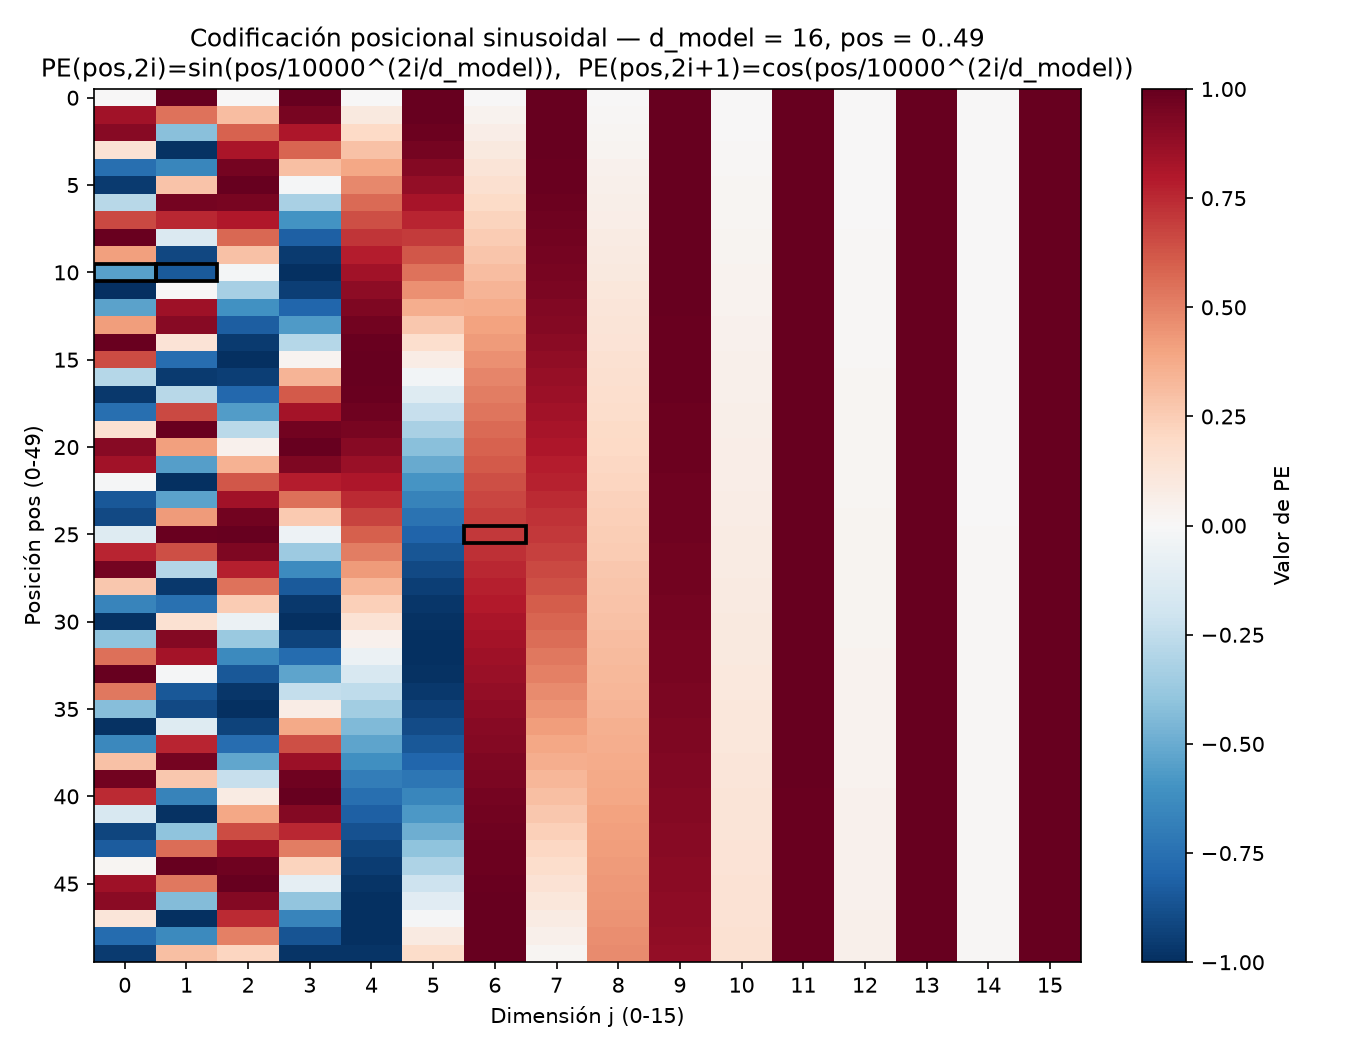

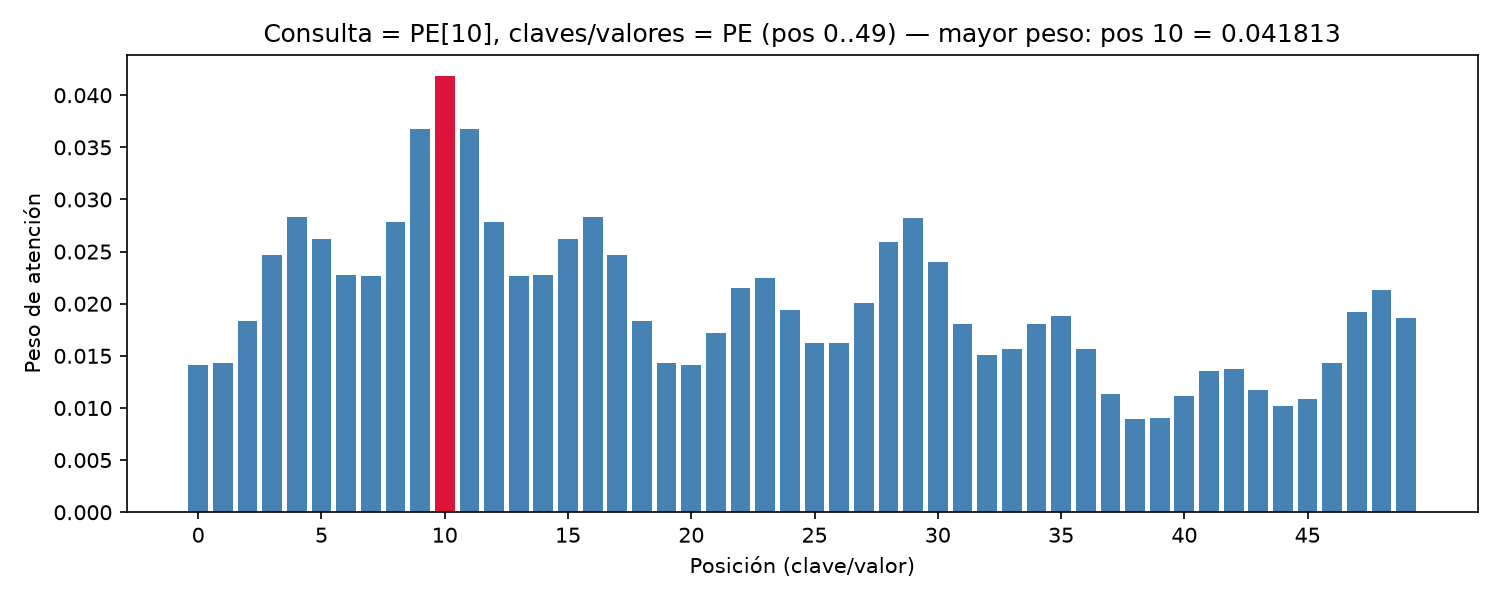

In [4]:
# Subtarea T3: código aprobado (se ejecuta en una copia: trabajo_nb/T3/)
os.chdir(RAIZ / 'trabajo_nb' / 'T3')

# -*- coding: utf-8 -*-
"""
T3 - Parte 3 - Codificación posicional sinusoidal (Vaswani et al., 2017).

1) Calcula PE(pos, 2i)   = sin(pos / 10000^(2i/d_model))
          PE(pos, 2i+1) = cos(pos / 10000^(2i/d_model))
   con d_model = 16 y pos = 0..49.
2) Reporta PE[10, 0], PE[10, 1] y PE[25, 6].
3) Dibuja la matriz 50x16 como mapa de calor (PNG).
4) Reutiliza la función de atención escalada de la Parte 1
   (softmax numéricamente estable, resta el máximo de cada fila) con
   consulta = PE[10] y claves/valores = matriz PE completa; identifica
   la posición que recibe el mayor peso y cuánto vale.

Salidas: resultados.json, T3_parte3_mapa_calor_PE.png,
         T3_parte3_pesos_atencion_PE10.png
"""

import json
import os

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ------------------------------------------------------------------
# 1) Función de atención escalada de la Parte 1 (se reutiliza aquí)
# ------------------------------------------------------------------
def softmax_estable(x, axis=-1):
    """Softmax numéricamente estable: resta el máximo de cada fila."""
    x_max = np.max(x, axis=axis, keepdims=True)
    e = np.exp(x - x_max)
    return e / np.sum(e, axis=axis, keepdims=True)


def atencion_escalada(Q, K, V):
    """
    Attention(Q, K, V) = softmax(Q K^T / sqrt(d_k)) V.

    Q: (n_q, d_k) | K: (n_k, d_k) | V: (n_k, d_v)
    Devuelve (puntajes, escalados, pesos, salida).
    """
    d_k = Q.shape[-1]
    puntajes = Q @ K.T                      # (n_q, n_k)
    escalados = puntajes / np.sqrt(d_k)     # (n_q, n_k)
    pesos = softmax_estable(escalados, axis=-1)
    salida = pesos @ V                      # (n_q, d_v)
    return puntajes, escalados, pesos, salida


# ------------------------------------------------------------------
# 2) Verificación: la misma función reproduce los resultados de T1
# ------------------------------------------------------------------
verif = {"T1_cargado": False}
ruta_t1 = os.path.join("entradas", "T1.json")
if os.path.exists(ruta_t1):
    try:
        with open(ruta_t1, "r", encoding="utf-8") as f:
            t1 = json.load(f)
        Q1 = np.asarray(t1["Q_2x4"], dtype=float)
        K1 = np.asarray(t1["K_3x4"], dtype=float)
        V1 = np.asarray(t1["V_3x2"], dtype=float)
        _, _, w1, s1 = atencion_escalada(Q1, K1, V1)
        w1_ref = np.asarray(t1["pesos_atencion_2x3"], dtype=float)
        s1_ref = np.asarray(t1["salida_atencion_2x2"], dtype=float)
        verif = {
            "T1_cargado": True,
            "d_k_T1": t1.get("d_k"),
            "max_abs_diff_pesos": float(np.max(np.abs(w1 - w1_ref))),
            "max_abs_diff_salida": float(np.max(np.abs(s1 - s1_ref))),
        }
        print("[Reutilización] Función de la Parte 1 verificada contra entradas/T1.json "
              f"(max diff pesos = {verif['max_abs_diff_pesos']:.2e}, "
              f"max diff salida = {verif['max_abs_diff_salida']:.2e})")
    except Exception as exc:  # un problema con T1 no debe interrumpir la subtarea
        verif = {"T1_cargado": False, "error": str(exc)}
        print("[Aviso] No se pudo verificar contra T1.json:", exc)

# ------------------------------------------------------------------
# 3) Codificación posicional sinusoidal (d_model = 16, pos = 0..49)
# ------------------------------------------------------------------
d_model = 16
n_pos = 50  # posiciones 0 a 49

pos = np.arange(n_pos, dtype=float)                 # (50,)
jdims = np.arange(d_model, dtype=float)             # dimensiones 0..15

# Exponente 2i/d_model de la fórmula del paper:
#   - dimensión par   j = 2i   -> exponente  j / d_model
#   - dimensión impar j = 2i+1 -> exponente (j-1) / d_model
exponente = np.where(jdims % 2 == 0, jdims, jdims - 1.0) / d_model   # (16,)
divisor = np.power(10000.0, exponente)                               # (16,)

angulos = pos[:, None] / divisor[None, :]                            # (50, 16)
PE = np.zeros((n_pos, d_model), dtype=float)
PE[:, 0::2] = np.sin(angulos[:, 0::2])   # dimensiones pares:  sin
PE[:, 1::2] = np.cos(angulos[:, 1::2])   # dimensiones impares: cos

PE_10_0 = float(PE[10, 0])
PE_10_1 = float(PE[10, 1])
PE_25_6 = float(PE[25, 6])

print("\nd_model =", d_model, "| posiciones = 0 ..", n_pos - 1)
print(f"PE[10, 0] = sin(10 / 10000^(0/16))  = {PE_10_0:.10f}")
print(f"PE[10, 1] = cos(10 / 10000^(0/16))  = {PE_10_1:.10f}")
print(f"PE[25, 6] = sin(25 / 10000^(6/16))  = {PE_25_6:.10f}")

# ------------------------------------------------------------------
# 4) Atención: consulta = PE[10], claves y valores = PE completa
# ------------------------------------------------------------------
consulta = PE[10:11, :]        # (1, 16)  -> aquí d_k = 16
claves = PE                    # (50, 16)
valores = PE                   # (50, 16)

puntajes, escalados, pesos, salida = atencion_escalada(consulta, claves, valores)
pesos_vec = pesos[0]           # (50,)
salida_vec = salida[0]         # (16,)

pos_mayor = int(np.argmax(pesos_vec))
valor_mayor = float(pesos_vec[pos_mayor])

print("\nAtención con consulta PE[10] (d_k = 16, sqrt(d_k) = %.1f):"
      % np.sqrt(consulta.shape[-1]))
orden = np.argsort(pesos_vec)[::-1][:5]
for p in orden:
    print(f"  pos {int(p):2d} -> peso = {pesos_vec[p]:.8f}")
print(f"Posición con mayor peso: {pos_mayor}")
print(f"Valor del mayor peso:    {valor_mayor:.10f}")
print(f"Suma de los pesos (debe ser 1): {float(np.sum(pesos_vec)):.10f}")

# ------------------------------------------------------------------
# 5) Figura 1: mapa de calor de la matriz PE (50 x 16)
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(PE, aspect="auto", cmap="RdBu_r", vmin=-1.0, vmax=1.0,
               interpolation="nearest", origin="upper")
ax.set_xlabel("Dimensión j (0-15)")
ax.set_ylabel("Posición pos (0-49)")
ax.set_title("Codificación posicional sinusoidal — d_model = 16, pos = 0..49\n"
             "PE(pos,2i)=sin(pos/10000^(2i/d_model)),  PE(pos,2i+1)=cos(pos/10000^(2i/d_model))")
ax.set_xticks(np.arange(0, d_model, 1))
ax.set_yticks(np.arange(0, n_pos, 5))
for (p, jj) in [(10, 0), (10, 1), (25, 6)]:   # marcar las celdas reportadas
    ax.add_patch(Rectangle((jj - 0.5, p - 0.5), 1, 1, fill=False,
                           edgecolor="black", linewidth=1.8))
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Valor de PE")
fig.tight_layout()
fig.savefig("T3_parte3_mapa_calor_PE.png", dpi=150)
plt.close(fig)
print("\nFigura guardada: T3_parte3_mapa_calor_PE.png")

# ------------------------------------------------------------------
# 6) Figura 2: pesos de atención de la consulta PE[10] sobre las 50 posiciones
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 4))
colores = ["crimson" if p == pos_mayor else "steelblue" for p in range(n_pos)]
ax.bar(np.arange(n_pos), pesos_vec, color=colores)
ax.set_xlabel("Posición (clave/valor)")
ax.set_ylabel("Peso de atención")
ax.set_title(f"Consulta = PE[10], claves/valores = PE (pos 0..49) — "
             f"mayor peso: pos {pos_mayor} = {valor_mayor:.6f}")
ax.set_xticks(np.arange(0, n_pos, 5))
fig.tight_layout()
fig.savefig("T3_parte3_pesos_atencion_PE10.png", dpi=150)
plt.close(fig)
print("Figura guardada: T3_parte3_pesos_atencion_PE10.png")

# ------------------------------------------------------------------
# 7) Guardar TODAS las cifras en resultados.json
# ------------------------------------------------------------------
resultados = {
    "d_model": int(d_model),
    "n_posiciones": int(n_pos),
    "PE_10_0": PE_10_0,
    "PE_10_1": PE_10_1,
    "PE_25_6": PE_25_6,
    "posicion_mayor_peso": int(pos_mayor),
    "valor_mayor_peso": valor_mayor,
    "d_k_atencion_PE": int(consulta.shape[-1]),
    "sqrt_d_k_atencion_PE": float(np.sqrt(consulta.shape[-1])),
    "PE_50x16": PE.tolist(),
    "puntajes_escalados_PE10_1x50": escalados[0].tolist(),
    "pesos_atencion_PE10_1x50": pesos_vec.tolist(),
    "salida_atencion_PE10_1x16": salida_vec.tolist(),
    "suma_pesos_atencion": float(np.sum(pesos_vec)),
    "verificacion_funcion_T1": verif,
}
with open("resultados.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False)
print("Resultados guardados en resultados.json")

os.chdir(RAIZ)
mostrar_figuras(RAIZ / 'trabajo_nb' / 'T3')

Se calcula la codificación sinusoidal

- $\mathrm{PE}(pos, 2i) = \sin\!\big(pos / 10000^{2i/d_{model}}\big)$
- $\mathrm{PE}(pos, 2i{+}1) = \cos\!\big(pos / 10000^{2i/d_{model}}\big)$

con $d_{model} = 16$ para las posiciones 0 a 49 (matriz PE de 50 × 16). La función de atención de la Parte 1 se reutiliza aquí y fue verificada contra las entradas de esa parte, con diferencia máxima de 0.0000 tanto en los pesos como en la salida.

### Valores reportados de PE

| Celda | Fórmula | Valor |
|---|---|---|
| PE[10, 0] | $\sin(10 / 10000^{0/16})$ | -0.5440 |
| PE[10, 1] | $\cos(10 / 10000^{0/16})$ | -0.8391 |
| PE[25, 6] | $\sin(25 / 10000^{6/16})$ | 0.7108 |

### Atención con la consulta PE[10]

Usando PE[10] como consulta y la matriz PE completa (50 × 16) como claves y valores, con $d_k = 16$ ($\sqrt{d_k} = 4.0$), la posición que recibe el mayor peso es la **posición 10**, con un peso de **0.0418** (la suma de los 50 pesos es 1.0000). Los pesos son simétricos respecto a la consulta: las posiciones 9 y 11, a distancia 1, reciben cada una 0.0368, y las posiciones 4 y 16, a distancia 6, reciben cada una 0.0283. Este patrón refleja que el producto punto entre codificaciones sinusoidales depende de la distancia relativa entre posiciones, y que cada posición atiende principalmente a sí misma.

La figura muestra el mapa de calor de la matriz PE (50 × 16), donde se aprecia la estructura de frecuencias decrecientes a lo largo de las dimensiones, junto con los pesos de atención de la consulta PE[10] sobre las 50 posiciones.



## Parte 4 — Pregunta conceptual

**¿Qué problema resuelve la división por √d_k?** Controla la magnitud de los puntajes $q \cdot k$. Si las componentes de $q$ y $k$ son variables aleatorias independientes con media 0 y varianza 1, su producto punto $q \cdot k = \sum_{i=1}^{d_k} q_i k_i$ tiene media 0 y varianza $d_k$ (Vaswani et al., 2017, nota al pie 4): al sumar $d_k$ términos, la dispersión de los puntajes crece con la dimensión. El experimento de la Parte 2 lo muestra empíricamente: sin escalar, con $d_k = 64$ el peso máximo es 0.9511 y la entropía cae a 0.3537 bits, y con $d_k = 512$ el peso máximo es 0.7503 con entropía 0.8114 bits. Es decir, el softmax se satura y la atención se vuelve casi determinista sobre una sola clave, incluso cuando las claves son ruido aleatorio sin estructura.

**¿Qué le pasaría al gradiente del softmax sin ella?** Cuando el softmax se satura, su salida es casi un vector one-hot. El gradiente del softmax respecto a sus puntajes es la matriz jacobiana $\mathrm{diag}(p) - p p^{\top}$: si $p$ tiene una componente casi igual a 1 y las demás casi 0, todas las entradas de esa matriz son casi 0. Sin el escalado, los gradientes que atraviesan los pesos de atención se vuelven extremadamente pequeños y el entrenamiento se frena precisamente en las cabezas con $d_k$ grandes. Es exactamente el efecto que describe el paper: para valores grandes de $d_k$, los productos punto crecen en magnitud, «empujando la función softmax a regiones donde tiene gradientes extremadamente pequeños», y para contrarrestarlo se escalan los productos punto por $1/\sqrt{d_k}$ (Vaswani et al., 2017, Scaled Dot-Product Attention, nota al pie 4).

**Cómo lo confirman las entropías de la Parte 2.** Al dividir por $\sqrt{d_k}$, los puntajes vuelven a una escala de varianza del orden de la unidad y el softmax regresa a una zona sensible: con $d_k = 64$ el peso máximo baja de 0.9511 a 0.2480 y la entropía sube de 0.3537 a 2.9802 bits; con $d_k = 512$ baja de 0.7503 a 0.1945 y la entropía sube de 0.8114 a 3.0363 bits. Entropías de ese tamaño corresponden a distribuciones mucho más planas sobre las 10 claves, con lo que el jacobiano del softmax no se anula y el gradiente puede fluir. Con $d_k = 4$ el cambio es pequeño (peso máximo 0.2049 → 0.1497; entropía 3.0792 → 3.2542 bits), coherente con que el problema solo se agrava cuando $d_k$ crece.

**Relación con el paper.** Vaswani et al. (2017) eligen la atención por producto punto frente a la aditiva porque, a complejidad teórica similar, es más rápida y eficiente en espacio en la práctica, ya que se apoya en código de multiplicación de matrices altamente optimizado. El precio del producto punto es precisamente el crecimiento de los puntajes con $d_k$, y el factor $1/\sqrt{d_k}$ de la «Scaled Dot-Product Attention» (Ec. 1 del paper) es la corrección: en su modelo, con $h = 8$ cabezas y $d_k = d_v = d_{model}/h = 64$, el escalado mantiene los puntajes en un rango donde el softmax no se satura y los gradientes permanecen útiles.